# Лабораторная работа №4. Байесовская сеть

Исследуем, как информация об учебной истории, времени учёбы и промежуточных оценках меняет вероятность итоговой оценки **не ниже 10 из 20**.

Используем открытый **Student Performance (UCI)** и самостоятельно задаём сеть из пяти переменных. Оцениваем таблицы условных вероятностей со сглаживанием, выполняем точный вероятностный вывод, последовательно добавляем evidence и удаляем одно ребро.

Это описательная модель распределения имеющихся данных. Качество прогноза на новых учениках и причинные эффекты здесь не оцениваются.

## 1. Подготовка

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 11})

## 2. Данные и смысл переменных
**Один объект** — запись об ученике по португальскому языку в одной из двух португальских школ. Математическую выборку не объединяем с этой: часть учеников присутствует в обоих файлах.

В исходных данных 33 столбца: оценки и демографические, семейные, социальные и школьные характеристики. Для небольшой, объяснимой сети выбираем пять:

| Поле | Значение в исходных данных | Возможная связь |
|---|---|---|
| `failures` | Показатель прошлых учебных неудач | Учебная история связана с нынешними привычками и результатами |
| `studytime` | Категория недельного времени учёбы: 1–4 | Затраты времени могут быть связаны с первой оценкой |
| `G1` | Оценка за первый период, шкала 0–20 | Ранний результат содержит информацию о следующем |
| `G2` | Оценка за второй период, шкала 0–20 | Более поздний результат содержит информацию об итоговом |
| `G3` | Итоговая оценка, шкала 0–20 | Интересующий результат |

Такие связи не означают, что изменение времени учёбы обязательно вызовет изменение оценки: мотивация, способности и другие факторы здесь не измеряются полностью.

In [ ]:
PATH = 'data/student-por.csv'
raw = pd.read_csv(PATH, sep=';')
FEATURES = ['failures', 'studytime', 'G1', 'G2', 'G3']

print(f'Размер исходной таблицы: {raw.shape[0]} строк, {raw.shape[1]} столбца')
print('Пропусков во всей таблице:', int(raw.isna().sum().sum()))
print('Полных дубликатов:', int(raw.duplicated().sum()))
display(raw[FEATURES].head())
display(raw[FEATURES].describe())

Размер исходной таблицы: 649 строк, 33 столбца
Пропусков во всей таблице: 0
Полных дубликатов: 0


,failures,studytime,G1,G2,G3
0,0,2,0,11,11
1,0,2,9,11,11
2,0,2,12,13,12
3,0,3,14,14,14
4,0,2,11,13,13


,failures,studytime,G1,G2,G3
count,649.0000,649.0000,649.0000,649.0000,649.0000
mean,0.2219,1.9307,11.3991,11.5701,11.9060
std,0.5932,0.8295,2.7453,2.9136,3.2307
min,0.0000,1.0000,0.0000,0.0000,0.0000
25%,0.0000,1.0000,10.0000,10.0000,10.0000
50%,0.0000,2.0000,11.0000,11.0000,12.0000
75%,0.0000,2.0000,13.0000,13.0000,14.0000
max,3.0000,4.0000,19.0000,19.0000,19.0000


### Подготовка и дискретизация

Пропусков и полных дубликатов нет, поэтому строки сохраняем. Нулевые оценки оставляем как значения исходной шкалы: оснований считать их пропусками нет.

Все пять переменных переводим в два состояния по заранее фиксированным правилам:

| Узел | Состояние 0 | Состояние 1 |
|---|---|---|
| `failures` | Не было прошлых неудач | Показатель прошлых неудач больше нуля |
| `studytime` | Категории 1–2: <2 или 2–5 ч/неделю | Категории 3–4: 5–10 или >10 ч/неделю |
| `G1`, `G2`, `G3` | Оценка <10 | Оценка ≥10 |

Порог 10 — половина шкалы, позволяющая одинаково и понятно разделить оценки всех трёх периодов. Далее слово **«успех» означает только оценку ≥10 в этой работе**. Для времени учёбы объединяем соседние категории; точную границу для ученика с ровно 5 часами из кодов восстановить нельзя. Историю объединяем в «нет / есть», чтобы не оценивать отдельные CPT для редких значений 2 и 3.

Дискретизация упрощает сеть и уменьшает число параметров, но теряет различия между, например, оценками 10 и 19. Границы не подбираются по результатам запросов.

Используем все наблюдения для описательной оценки распределения. Train/test не выделяем, потому что не сравниваем предсказательные алгоритмы и не заявляем качество на новых данных. Частоты ниже служат проверкой согласованности с той же выборкой, а не независимым тестом.

In [3]:
data = pd.DataFrame(index=raw.index)
data['failures'] = (raw['failures'] > 0).astype(int)
data['studytime'] = (raw['studytime'] >= 3).astype(int)
for grade in ['G1', 'G2', 'G3']:
    data[grade] = (raw[grade] >= 10).astype(int)

state_counts = pd.DataFrame({node: data[node].value_counts().reindex([0, 1], fill_value=0)
                             for node in FEATURES}).T
state_counts.columns = ['N(0)', 'N(1)']
state_counts['Доля состояния 1'] = data.mean()
display(state_counts)
display(pd.crosstab(raw['failures'], columns='N').rename_axis('Исходное failures'))
display(pd.crosstab(raw['studytime'], columns='N').rename_axis('Исходное studytime'))

,N(0),N(1),Доля состояния 1
failures,549,100,0.1541
studytime,517,132,0.2034
G1,157,492,0.7581
G2,145,504,0.7766
G3,100,549,0.8459


col_0,N
Исходное failures,
0,549
1,70
2,16
3,14


col_0,N
Исходное studytime,
1,212
2,305
3,97
4,35


## 3. Вопросы до построения сети

1. Как изменится вероятность итоговой оценки ≥10, если во втором периоде оценка была <10?
2. Какова вероятность итоговой оценки ≥10, если одновременно известны прошлые неудачи и оценка второго периода <10? Добавляет ли история информацию к промежуточной оценке?
3. Как изменится вероятность наличия прошлых неудач, если стала известна итоговая оценка <10? Это обратный диагностический вывод, а не прогноз прошлого или доказательство причины.

Для каждого вопроса сравним вероятность без evidence и с evidence. Затем для `G3` последовательно узнаем историю, оценку первого периода и оценку второго периода.

## 4. Самостоятельная структура сети

Задаём связи по смыслу переменных и порядку событий, а не выбираем рёбра по максимуму корреляции.

| Ребро | Почему включено и почему выбрано направление |
|---|---|
| `failures → studytime` | Текущие учебные привычки могут различаться в зависимости от прошлой истории. История относится к прошлому, время учёбы — к текущему состоянию; это вероятностная гипотеза, не установленный эффект прошлых неудач |
| `failures → G1` | Прошлая учебная история содержит информацию о результатах первого периода текущего курса |
| `studytime → G1` | Учебная нагрузка может быть связана с первым результатом. Направление — выбранная факторизация: время анкеты не позволяет исключить обратную реакцию привычек на оценки |
| `G1 → G2` | Первая оценка предшествует второй и отражает раннее состояние знаний и учебного процесса |
| `G2 → G3` | Вторая оценка предшествует итоговой; это использование более поздней информации о том же курсе |
| `failures → G3` | Прошлая история может содержать дополнительную информацию, которую грубая бинарная оценка `G2` не сохраняет полностью |

Обозначения: `F = failures`, `S = studytime`, `A = G1`, `B = G2`, `Y = G3`.

$$
P(F,S,A,B,Y)=P(F)P(S\mid F)P(A\mid F,S)P(B\mid A)P(Y\mid F,B).
$$

Например, сеть предполагает `G3 ⟂ {G1, studytime} | {failures, G2}` и `G2 ⟂ {failures, studytime} | G1`. Это упрощения, а не факты, доказанные данными. Дополнительные прямые стрелки могли бы ослабить эти допущения, но потребовали бы больше параметров.

Наличие `G2` допустимо для вывода после второго периода. Такой запрос нельзя выдавать за прогноз в начале учебного года.

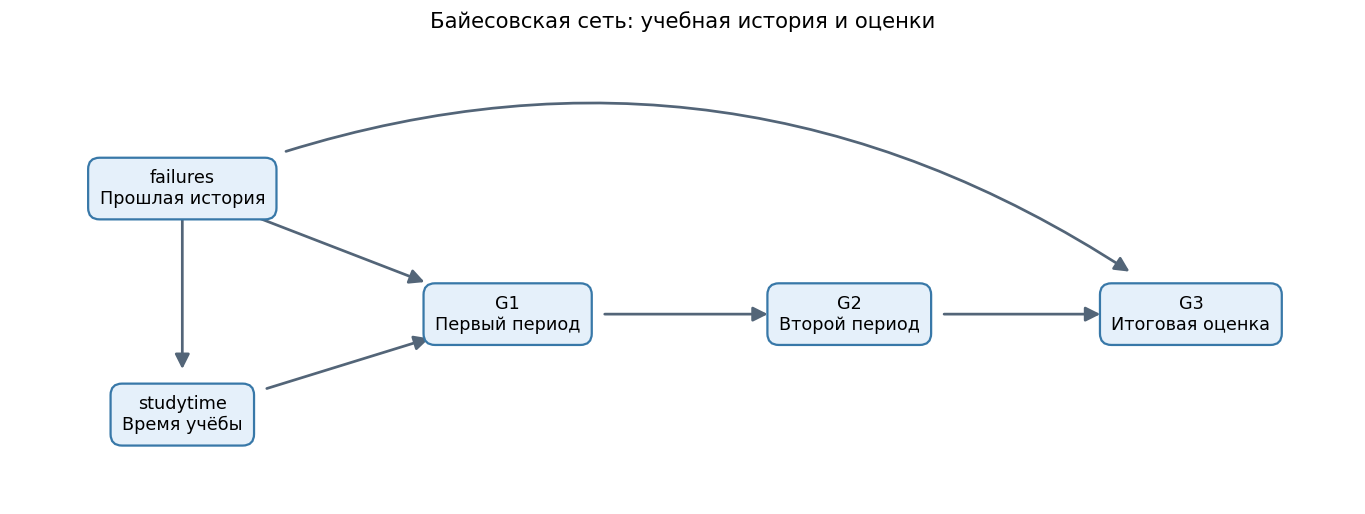

In [4]:
# Порядок узлов топологический: каждый родитель стоит раньше ребёнка.
PARENTS = {
    'failures': [],
    'studytime': ['failures'],
    'G1': ['failures', 'studytime'],
    'G2': ['G1'],
    'G3': ['failures', 'G2'],
}
NODES = list(PARENTS)
for child, parents in PARENTS.items():
    assert all(NODES.index(parent) < NODES.index(child) for parent in parents)

def draw_network(parents, title):
    positions = {'failures': (0, 1.0), 'studytime': (0, -0.8),
                 'G1': (2.0, 0), 'G2': (4.1, 0), 'G3': (6.2, 0)}
    labels = {'failures': 'failures\nПрошлая история',
              'studytime': 'studytime\nВремя учёбы',
              'G1': 'G1\nПервый период', 'G2': 'G2\nВторой период',
              'G3': 'G3\nИтоговая оценка'}
    fig, ax = plt.subplots(figsize=(12, 4.6))
    boxes = {}
    for node, (x, y) in positions.items():
        label = ax.text(x, y, labels[node], ha='center', va='center', zorder=2,
                        bbox={'boxstyle': 'round,pad=0.65', 'facecolor': '#e5f0fa',
                              'edgecolor': '#3878a8', 'linewidth': 1.4})
        boxes[node] = label.get_bbox_patch()
    ax.set(xlim=(-1.05, 7.2), ylim=(-1.5, 2.2), title=title)
    ax.axis('off')
    fig.tight_layout()
    fig.canvas.draw()
    for child, node_parents in parents.items():
        for parent in node_parents:
            curve = -0.28 if (parent, child) == ('failures', 'G3') else 0
            ax.add_patch(FancyArrowPatch(positions[parent], positions[child],
                         patchA=boxes[parent], patchB=boxes[child],
                         connectionstyle=f'arc3,rad={curve}', arrowstyle='-|>',
                         mutation_scale=19, color='#536578', linewidth=1.7,
                         shrinkA=3, shrinkB=4, zorder=1))
    plt.show()

draw_network(PARENTS, 'Байесовская сеть: учебная история и оценки')

## 5. Оценка таблиц условных вероятностей

Для каждого узла и каждой комбинации состояний родителей считаем частоты. Используем сглаживание Лапласа с заранее зафиксированным `alpha=1`:

$$
\widehat P(X=x\mid Pa(X)=u)=\frac{N(X=x,Pa(X)=u)+\alpha}{N(Pa(X)=u)+2\alpha}.
$$

Двойка в знаменателе — число состояний узла. Это апостериорное среднее при симметричном Dirichlet(1,1) для каждой строки CPT. Оно немного сдвигает вероятности к 0.5 и не позволяет отсутствию сочетания в небольшой выборке сделать событие невозможным. Это не означает, что редкие сочетания оценены надёжно.

Без сглаживания оценка была бы обычной долей `n1 / n`. Ниже показываем и долю, и сглаженную вероятность, и число наблюдений. Для пяти бинарных узлов существуют $2^5=32$ совместных состояния; сеть оценивает 13 свободных параметров вместо 31 в произвольном совместном распределении.

In [5]:
ALPHA = 1.0

def fit_cpts(frame, parents, alpha=1.0):
    cpts = {}
    for node, node_parents in parents.items():
        rows = []
        for values in product([0, 1], repeat=len(node_parents)):
            context = dict(zip(node_parents, values))
            mask = pd.Series(True, index=frame.index)
            for parent, value in context.items():
                mask &= frame[parent].eq(value)
            counts = frame.loc[mask, node].value_counts().reindex([0, 1], fill_value=0)
            n0, n1 = int(counts[0]), int(counts[1])
            n = n0 + n1
            rows.append({**context, 'n0': n0, 'n1': n1, 'n': n,
                         'empirical_p1': n1 / n if n else np.nan,
                         'p0': (n0 + alpha) / (n + 2 * alpha),
                         'p1': (n1 + alpha) / (n + 2 * alpha)})
        cpts[node] = pd.DataFrame(rows)
    return cpts

cpts = fit_cpts(data, PARENTS, ALPHA)
support = pd.DataFrame([
    {'Узел': node, 'Родители': ', '.join(PARENTS[node]) or 'нет',
     'Строк CPT': len(table), 'Минимальный N контекста': int(table['n'].min()),
     'Пустых контекстов': int(table['n'].eq(0).sum())}
    for node, table in cpts.items()
])
display(support)
print('Свободных параметров:', sum(len(table) for table in cpts.values()))
for node in ['studytime', 'G1', 'G3']:
    display(Markdown(f'**CPT для `{node}`: `p1` = P({node}=1 | родители)**'))
    display(cpts[node])

,Узел,Родители,Строк CPT,Минимальный N контекста,Пустых контекстов
0,failures,нет,1,649,0
1,studytime,failures,2,100,0
2,G1,"failures, studytime",4,10,0
3,G2,G1,2,157,0
4,G3,"failures, G2",4,36,0


Свободных параметров: 13


**CPT для `studytime`: `p1` = P(studytime=1 | родители)**

,failures,n0,n1,n,empirical_p1,p0,p1
0,0,427,122,549,0.2222,0.7768,0.2232
1,1,90,10,100,0.1000,0.8922,0.1078


**CPT для `G1`: `p1` = P(G1=1 | родители)**

,failures,studytime,n0,n1,n,empirical_p1,p0,p1
0,0,0,82,345,427,0.8080,0.1935,0.8065
1,0,1,5,117,122,0.9590,0.0484,0.9516
2,1,0,64,26,90,0.2889,0.7065,0.2935
3,1,1,6,4,10,0.4000,0.5833,0.4167


**CPT для `G3`: `p1` = P(G3=1 | родители)**

,failures,G2,n0,n1,n,empirical_p1,p0,p1
0,0,0,42,39,81,0.4815,0.5181,0.4819
1,0,1,9,459,468,0.9808,0.0213,0.9787
2,1,0,47,17,64,0.2656,0.7273,0.2727
3,1,1,2,34,36,0.9444,0.0789,0.9211


### Что видно из CPT

Проанализируем влияние истории на время учёбы, малый контекст для первой оценки и различия итогового результата при одной и той же второй оценке. Все числа ниже получены из CPT выполненного запуска.

In [6]:
def cpt_context(node, evidence):
    table = cpts[node]
    mask = pd.Series(True, index=table.index)
    for key, value in evidence.items():
        mask &= table[key].eq(value)
    return table.loc[mask].iloc[0]

- При отсутствии прошлых неудач высокая категория времени учёбы встречается в **122/549 = 22.2%** случаев; при их наличии — в **10/100 = 10.0%**. Поэтому независимость этих двух узлов была бы заметным упрощением. Это ассоциация; она не доказывает, что прошлые неудачи уменьшают время учёбы.
- Самый малый родительский контекст: `failures=1, studytime=1`, **N=10**. Первая оценка ≥10 есть у 4 учеников: эмпирическая доля 40.0%, после сглаживания 41.7%. Объёма достаточно для компактного учебного примера, но недостаточно для уверенного вывода об этой подгруппе.
- При `G2=0` вероятность `G3=1` после сглаживания составляет **48.2%** без прошлых неудач и **27.3%** при их наличии. Оценка второго периода <10 не делает итог ≥10 невозможным: граница 10 груба, между периодами результат может измениться. Из этих данных нельзя установить причину улучшения.
- При `G2=1, failures=0` эмпирическая доля успеха равна 98.1% при N=468. Сильная связь соседних оценок ожидаема для одного курса, но не означает независимую проверку точности модели.

## 6. Точный вероятностный вывод

Перебираем все 32 комбинации пяти бинарных переменных и для каждой перемножаем соответствующие вероятности из CPT. Получаем полное совместное распределение без моделирования случайных выборок.

Для запроса с evidence $E=e$ отбираем совместные состояния, согласующиеся с наблюдениями, суммируем вероятности по скрытым переменным и нормируем:

$$
P(X=x\mid E=e)=\frac{\sum_{z}P(X=x,E=e,Z=z)}{\sum_{x',z}P(X=x',E=e,Z=z)}.
$$

Evidence — наблюдение, например `G2=0`. Это условие, а не вмешательство `do(G2=0)`. Вывод можно выполнять в обе стороны относительно стрелок.

In [7]:
def make_joint(cpts, parents):
    nodes = list(parents)
    rows = []
    for values in product([0, 1], repeat=len(nodes)):
        state = dict(zip(nodes, values))
        probability = 1.0
        for node, node_parents in parents.items():
            table = cpts[node]
            mask = pd.Series(True, index=table.index)
            for parent in node_parents:
                mask &= table[parent].eq(state[parent])
            probability *= table.loc[mask, f'p{state[node]}'].item()
        rows.append({**state, 'prob': probability})
    return pd.DataFrame(rows)

def query(joint, target, evidence=None):
    evidence = evidence or {}
    mask = pd.Series(True, index=joint.index)
    for node, value in evidence.items():
        mask &= joint[node].eq(value)
    selected = joint.loc[mask]
    mass = selected['prob'].sum()
    if mass <= 0:
        raise ValueError('Evidence имеет нулевую вероятность')
    return selected.groupby(target)['prob'].sum().reindex([0, 1], fill_value=0) / mass

def observed_subset(evidence):
    mask = pd.Series(True, index=data.index)
    for node, value in evidence.items():
        mask &= data[node].eq(value)
    return data.loc[mask]

joint = make_joint(cpts, PARENTS)
print(f'Совместных состояний: {len(joint)}; сумма вероятностей: {joint.prob.sum():.12f}')
display(joint.head(8))

Совместных состояний: 32; сумма вероятностей: 1.000000000000


,failures,studytime,G1,G2,G3,prob
0,0,0,0,0,0,0.0447
1,0,0,0,0,1,0.0416
2,0,0,0,1,0,0.0009
3,0,0,0,1,1,0.0399
4,0,0,1,0,0,0.0216
5,0,0,1,0,1,0.0201
6,0,0,1,1,0,0.0104
7,0,0,1,1,1,0.4771


### Три заранее сформулированных запроса

В таблице `P до` — маргинальная вероятность по сети, `P после` — условная по той же сети. Изменение измеряем в **процентных пунктах**. Рядом показываем эмпирическую долю в подгруппе и её размер: малую подгруппу нельзя считать надёжным подтверждением результата.

In [8]:
QUESTIONS = [
    ('1. Итог при низкой G2', 'G3', {'G2': 0}),
    ('2. Итог при истории и низкой G2', 'G3', {'failures': 1, 'G2': 0}),
    ('3. История при низком итоге', 'failures', {'G3': 0}),
]
query_rows = []
for question, target, evidence in QUESTIONS:
    before = query(joint, target)[1]
    after = query(joint, target, evidence)[1]
    subset = observed_subset(evidence)
    query_rows.append({'Вопрос': question, 'Событие': f'{target}=1',
                       'Evidence': str(evidence), 'P до': before, 'P после': after,
                       'Изменение, п.п.': 100 * (after - before),
                       'Эмпирическая доля': subset[target].mean(), 'N evidence': len(subset)})
query_results = pd.DataFrame(query_rows).set_index('Вопрос')
display(query_results)

,Событие,Evidence,P до,P после,"Изменение, п.п.",Эмпирическая доля,N evidence
Вопрос,,,,,,,
1. Итог при низкой G2,G3=1,{'G2': 0},0.8463,0.4106,-43.5679,0.3862,145
2. Итог при истории и низкой G2,G3=1,"{'failures': 1, 'G2': 0}",0.8463,0.2727,-57.3527,0.2656,64
3. История при низком итоге,failures=1,{'G3': 0},0.1551,0.4036,24.8427,0.4900,100


1. При оценке второго периода <10 вероятность итоговой оценки ≥10 меняется с **84.6% до 41.1%**. Вторая оценка напрямую связана с итоговой в графе и даёт более позднюю информацию о текущем курсе.
2. Если дополнительно известны прошлые неудачи, вероятность равна **27.3%**, на **-13.8 п.п.** относительно первого запроса. История сохраняет дополнительную связь с итогом через ребро `failures → G3`. Это характеристика наблюдаемых групп, а не судьба отдельного ученика.
3. При итоговой оценке <10 вероятность прошлых неудач меняется с **15.5% до 40.4%**. Наблюдение результата обновляет представление о скрытой истории. Итоговая оценка не могла изменить прошлое; обратный вывод не меняет направления времени.

Модельные вероятности могут отличаться от эмпирических долей из-за сглаживания и условных независимостей графа. Совпадение с частотой той же выборки не доказывает качество на новых данных.

## 7. Последовательное добавление evidence

Следим за распределением `G3`. Рассмотрим историю с прошлыми неудачами, затем низкую первую оценку и после неё вторую оценку ≥10. Последнее наблюдение может изменить впечатление от ранней информации: мы узнаём о более позднем результате.

,P(G3 < 10),P(G3 ≥ 10),N evidence,Эмпирическая доля G3 ≥ 10
Шаг,,,,
Без сведений,0.1537,0.8463,649,0.8459
Есть прошлые неудачи,0.3999,0.6001,100,0.5100
Также G1 < 10,0.5193,0.4807,70,0.3857
Также G2 ≥ 10,0.0789,0.9211,15,0.9333


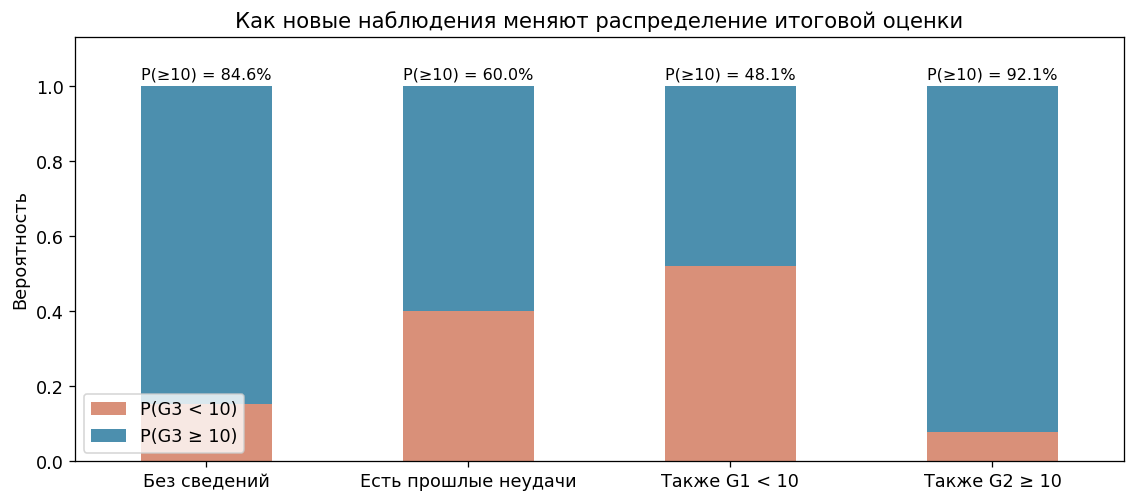

In [9]:
EVIDENCE_STEPS = [
    ('Без сведений', {}),
    ('Есть прошлые неудачи', {'failures': 1}),
    ('Также G1 < 10', {'failures': 1, 'G1': 0}),
    ('Также G2 ≥ 10', {'failures': 1, 'G1': 0, 'G2': 1}),
]
evidence_rows = []
for label, evidence in EVIDENCE_STEPS:
    posterior = query(joint, 'G3', evidence)
    subset = observed_subset(evidence)
    evidence_rows.append({'Шаг': label, 'P(G3 < 10)': posterior[0],
                          'P(G3 ≥ 10)': posterior[1], 'N evidence': len(subset),
                          'Эмпирическая доля G3 ≥ 10': subset['G3'].mean()})
evidence_results = pd.DataFrame(evidence_rows).set_index('Шаг')
display(evidence_results)

fig, ax = plt.subplots(figsize=(10, 4.5))
evidence_results[['P(G3 < 10)', 'P(G3 ≥ 10)']].plot.bar(
    stacked=True, color=['#d99079', '#4c8fae'], ax=ax, rot=0)
ax.set(title='Как новые наблюдения меняют распределение итоговой оценки',
       xlabel='', ylabel='Вероятность', ylim=(0, 1.13))
for i, p in enumerate(evidence_results['P(G3 ≥ 10)']):
    ax.text(i, 1.02, f'P(≥10) = {p:.1%}', ha='center', fontsize=10)
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()

Вероятность успеха последовательно равна **84.6% → 60.0% → 48.1% → 92.1%**.
Прошлая история и низкая `G1` снижают её: работают пути от `failures` и цепочка `G1 → G2 → G3`.
Но известная высокая `G2` обновляет вывод в сторону успеха: это более позднее свидетельство о результате того же курса.

После фиксации `failures` и `G2` первая оценка больше не влияет на `G3` **в данной структуре**: все родители `G3` известны. Это модельное допущение, а не универсальное свойство школьных оценок.
Последней комбинации evidence соответствуют **15** наблюдений; вывод для неё ограничен малым объёмом данных.

## 8. Удаление одного ребра

Удалим `failures → G3`. Остальные связи, дискретизация, строки данных и `alpha=1` сохраняются. **Заново оценим CPT по данным**: теперь у `G3` единственный родитель `G2`. Повторим второй запрос и для сравнения возьмём обе истории при одной и той же `G2=0`.

В изменённой сети появляется допущение `G3 ⟂ failures | G2`. История всё ещё связана с итогом в модели без фиксированной `G2` через пути к промежуточным оценкам.

In [10]:
PARENTS_REDUCED = {node: list(parents) for node, parents in PARENTS.items()}
PARENTS_REDUCED['G3'].remove('failures')
cpts_reduced = fit_cpts(data, PARENTS_REDUCED, ALPHA)
joint_reduced = make_joint(cpts_reduced, PARENTS_REDUCED)
display(Markdown('**Новая CPT для `G3`**'))
display(cpts_reduced['G3'])

structure_rows = []
for history in [0, 1]:
    evidence = {'failures': history, 'G2': 0}
    full_p = query(joint, 'G3', evidence)[1]
    reduced_p = query(joint_reduced, 'G3', evidence)[1]
    structure_rows.append({'Evidence': str(evidence), 'Исходная сеть': full_p,
                           'Без failures → G3': reduced_p,
                           'Изменение, п.п.': 100 * (reduced_p - full_p),
                           'N evidence': len(observed_subset(evidence))})
structure_results = pd.DataFrame(structure_rows)
display(structure_results)

**Новая CPT для `G3`**

,G2,n0,n1,n,empirical_p1,p0,p1
0,0,89,56,145,0.3862,0.6122,0.3878
1,1,11,493,504,0.9782,0.0237,0.9763


,Evidence,Исходная сеть,Без failures → G3,"Изменение, п.п.",N evidence
0,"{'failures': 0, 'G2': 0}",0.4819,0.3878,-9.4173,81
1,"{'failures': 1, 'G2': 0}",0.2727,0.3878,11.5028,64


Для повторённого второго запроса вероятность изменилась с **27.3% до 38.8%**, то есть на **+11.5 п.п.**
После удаления ребра при известной `G2` модель объединяет учеников с разной историей в одну CPT. Поэтому обе строки новой сети дают одинаковую вероятность, хотя в исходной сети она различалась.

Изменение вызвано новым набором условных независимостей и переоценкой вероятностей в объединённых группах. При этом из одного такого сравнения нельзя заключить, что исходный граф истинный или лучше предсказывает новые данные: для этого понадобилась бы отдельная проверка качества.

## 9. Проверка вычислений

Проверяем нормировку CPT и совместных распределений, согласованность точного вывода с CPT при фиксированных родителях, формулу Байеса для обратного запроса и условную независимость, введённую удалением ребра.

In [11]:
for model_cpts, model_joint in [(cpts, joint), (cpts_reduced, joint_reduced)]:
    for table in model_cpts.values():
        assert np.allclose(table['p0'] + table['p1'], 1)
        assert (table[['p0', 'p1']].to_numpy() > 0).all()
    assert len(model_joint) == 32
    assert np.isclose(model_joint['prob'].sum(), 1)

# При известных родителях G3 точный вывод должен вернуть строку CPT.
for history, second_grade in product([0, 1], repeat=2):
    evidence = {'failures': history, 'G2': second_grade}
    expected = cpt_context('G3', evidence)['p1']
    assert np.isclose(query(joint, 'G3', evidence)[1], expected)

# Один условный ответ независимо пересчитываем непосредственно из данных.
subset = data.loc[data['failures'].eq(1) & data['G2'].eq(0), 'G3']
assert np.isclose(query(joint, 'G3', {'failures': 1, 'G2': 0})[1],
                  (subset.sum() + 1) / (len(subset) + 2))

# P(F=1 | Y=0) P(Y=0) = P(Y=0 | F=1) P(F=1).
assert np.isclose(query(joint, 'failures', {'G3': 0})[1] * query(joint, 'G3')[0],
                  query(joint, 'G3', {'failures': 1})[0] * query(joint, 'failures')[1])
assert np.isclose(query(joint_reduced, 'G3', {'failures': 0, 'G2': 0})[1],
                  query(joint_reduced, 'G3', {'failures': 1, 'G2': 0})[1])
assert np.isclose(query(joint, 'G3', {'failures': 1, 'G1': 0, 'G2': 1})[1],
                  query(joint, 'G3', {'failures': 1, 'G2': 1})[1])
print('Проверки пройдены: нормировка, CPT, частоты, формула Байеса и условные независимости.')

Проверки пройдены: нормировка, CPT, частоты, формула Байеса и условные независимости.


## 10. Причинность и ограничения

**Построенную сеть нельзя считать установленной причинной моделью.** Данные наблюдательные, а рёбра предложены как содержательно осмысленная вероятностная факторизация. Даже временной порядок оценок не доказывает, что изменение одной оценки само по себе вызовет изменение следующей: обе могут зависеть от знаний, преподавания и правил выставления итогового балла.

Направление `studytime → G1` особенно условно: анкета не доказывает, что учебные привычки измерены до первой оценки. Ученик мог начать заниматься больше после трудностей. Скрытые способности и мотивация могут влиять на обе переменные. Поэтому `P(G3 | studytime=1)` нельзя читать как эффект принудительного увеличения времени учёбы.

Только по наблюдательным данным направление рёбер часто не определяется однозначно: разные DAG могут кодировать один набор условных независимостей. Временной порядок и предметные сведения ограничивают варианты, но для причинного вывода нужны дополнительные допущения, информация о сборе данных или интервенционный дизайн.

Ограничения модели:

- Небольшая выборка из двух школ по одному предмету не описывает всех учеников; в малом родительском контексте всего 10 строк.
- Дискретизация теряет информацию. Итог ≥10 — выбранное здесь определение успеха, а не полное описание знаний.
- Граф исключает возможные дополнительные связи и скрытые факторы. Его условные независимости не доказаны.
- Сглаживание предотвращает нули, но не устраняет неопределённость малых групп; доверительные или апостериорные интервалы здесь не оценивались.
- Более поздние оценки доступны лишь после соответствующих периодов. Результаты с `G2` не характеризуют ранний прогноз.
- Эмпирические частоты и модель оценены по одним данным. Независимой оценки точности и проверки переноса на новые школы нет.

## 11. Итог

Ниже — выводы по выполненным вычислениям, а не ожидаемые результаты до запуска.

1. Построена сеть из **5 переменных и 6 рёбер**, оценены **13 свободных параметров** по 649 наблюдениям. Изучены CPT для времени учёбы, первой и итоговой оценок.
2. Интересна связь итоговой оценки со второй: при `G2<10` вероятность итога ≥10 составляет **41.1%** против **84.6%** без сведений. Прошлая история добавляет информацию: при прошлых неудачах и той же низкой `G2` вероятность равна **27.3%**.
3. Новые сведения могут менять вывод в разные стороны. В последовательном эксперименте вероятность успеха менялась так: **84.6% → 60.0% → 48.1% → 92.1%**. Известная высокая `G2` обновила вывод после неблагоприятной ранней информации.
4. После удаления `failures → G3` ответ второго запроса изменился на **+11.5 п.п.** Структура влияет на то, какую информацию модель сохраняет при условном выводе.
5. Полученные вероятности описывают выбранную выборку при заданном графе и дискретизации. Они не доказывают причинность, индивидуальную неизбежность результата или качество прогноза на новых учениках.